# Segmentacja klientów sklepu internetowego metodą K-means

**Cel:** sprawdzić, czy na podstawie zachowań zakupowych można wyróżnić interpretowalne segmenty klientów.

Pytania pomocnicze:
1. Jak różnią się klienci pod względem częstotliwości i wartości zakupów?
2. Ile segmentów jest uzasadnione w świetle wybranych metryk i interpretacji?
3. Czym charakteryzują się uzyskane segmenty i jakie są ograniczenia wnioskowania?

Cała logika (wczytanie, czyszczenie, cechy, segmentacja, wykresy) znajduje się w pakiecie `analiza/`.
Notebook, aplikacja Streamlit i testy korzystają z tych samych funkcji.

In [1]:
%matplotlib inline
import sys
from pathlib import Path

KATALOG_PROJEKTU = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(KATALOG_PROJEKTU))
KATALOG_WYKRESOW = KATALOG_PROJEKTU / "figures"

import pandas as pd

from analiza import czyszczenie, eda, wykresy
from analiza.wczytanie import URL_OPISU, opis_zbioru, slownik_kolumn, wczytaj_dane



def format_liczby(x: float) -> str:
    # liczby w tabelach w zapisie polskim: spacja tysięcy, przecinek dziesiętny
    cyfry = 3 if abs(x) < 10 else 2
    return f"{x:,.{cyfry}f}".replace(",", " ").replace(".", ",")


pd.set_option("display.float_format", format_liczby)
pd.set_option("display.max_colwidth", 120)

## 1. Opis danych

**Źródło:** UCI Machine Learning Repository – zbiór *Online Retail* (licencja CC BY 4.0).
Zawiera wszystkie transakcje brytyjskiego sklepu internetowego sprzedającego upominki
(wielu klientów to hurtownicy). **Jednostka obserwacji** w danych surowych to jedna pozycja
faktury (produkt na fakturze); jednostką analizy w segmentacji będzie **klient**.

In [2]:
surowe = wczytaj_dane()
print("Źródło:", URL_OPISU)
pd.Series(opis_zbioru(surowe), name="wartość").to_frame()

Źródło: https://archive.ics.uci.edu/dataset/352/online+retail


,wartość
liczba_wierszy,541909
liczba_kolumn,8
data_od,2010-12-01 08:26:00
data_do,2011-12-09 12:50:00
liczba_faktur,25900
liczba_klientow,4372
liczba_produktow,4070
liczba_krajow,38


In [3]:
slownik_kolumn(surowe)

,kolumna,typ,przyklad,znaczenie
0,InvoiceNo,str,536365,Numer faktury (6 cyfr); prefiks 'C' oznacza fakturę anulującą (korektę)
1,StockCode,str,85123A,"Kod produktu (5 cyfr, czasem z literą); kody specjalne, np. POST, M, D, oznaczają pozycje nietowarowe"
2,Description,str,WHITE HANGING HEART T-LIGHT HOLDER,Nazwa produktu
3,Quantity,int64,6,"Liczba sztuk w pozycji faktury; wartości ujemne to anulowania, zwroty i korekty"
4,InvoiceDate,datetime64[us],2010-12-01 08:26:00,Data i godzina wystawienia faktury
5,UnitPrice,float64,2.55,Cena jednostkowa w funtach szterlingach (GBP)
6,CustomerID,Int64,17850,Pięciocyfrowy identyfikator klienta
7,Country,str,United Kingdom,Kraj zamieszkania klienta


In [4]:
surowe.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,"2,550",17850,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,"3,390",17850,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,"2,750",17850,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,"3,390",17850,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,"3,390",17850,United Kingdom


Zbiór obejmuje ok. 12 miesięcy (01.12.2010–09.12.2011), 541 909 pozycji faktur w 8 kolumnach,
25 900 faktur, 4 372 klientów, 4 070 kodów produktów i 38 krajów. Kluczowe pola dla segmentacji to
`CustomerID` (kto), `InvoiceNo` i `InvoiceDate` (kiedy i w ramach którego zamówienia) oraz
`Quantity` × `UnitPrice` (ile wydał).

## 2. Kontrola jakości danych

Sprawdzamy typy, braki, duplikaty oraz wartości niedozwolone i nietypowe.

In [5]:
czyszczenie.raport_jakosci(surowe)

,typ,braki,braki_proc,unikalne,min,max
kolumna,,,,,,
InvoiceNo,str,0,"0,000",25900,None,None
StockCode,str,0,"0,000",4070,None,None
Description,str,1454,"0,270",4211,None,None
Quantity,int64,0,"0,000",722,-80995,80995
InvoiceDate,datetime64[us],0,"0,000",23260,2010-12-01 08:26:00,2011-12-09 12:50:00
UnitPrice,float64,0,"0,000",1630,"-11 062,06","38 970,00"
CustomerID,Int64,135080,"24,93",4372,12346,18287
Country,str,0,"0,000",38,None,None


In [6]:
czyszczenie.podsumowanie_problemow(surowe).to_frame()

,liczba
wiersze,541909
pelne duplikaty,5268
brak CustomerID,135080
brak Description,1454
wiersze faktur anulujących (C),9288
Quantity <= 0,10624
Quantity < 0 poza fakturami C,1336
UnitPrice = 0,2515
UnitPrice < 0,2
nietypowy format InvoiceNo,3


Najważniejsze problemy:

* **Brak `CustomerID`** w 135 080 wierszach (24,9%) – tych transakcji nie da się przypisać do klienta.
* **5 268 pełnych duplikatów** – ta sama faktura, produkt, ilość, cena i czas co do minuty.
* **Faktury anulujące** (numer z prefiksem `C`, 9 288 pozycji) – wszystkie mają ujemną ilość;
  w tym zbiorze zwroty i anulowania zamówień są księgowane tym samym typem dokumentu.
* **Ujemne ilości poza fakturami `C`** (1 336 wierszy) – korekty magazynowe (np. towar uszkodzony),
  wszystkie bez identyfikatora klienta i z ceną 0.
* **Ceny niedodatnie:** 2 515 pozycji z ceną 0 i 2 z ceną ujemną (korekta złego długu, faktury z prefiksem `A`).
* **Pozycje nietowarowe** – kody `POST`, `DOT`, `C2` (wysyłka), `M` (korekty ręczne), `D` (rabat),
  `BANK CHARGES`, `CRUK`, `AMAZONFEE` i inne – nie są zakupem produktu.

In [7]:
surowe.loc[czyszczenie.czy_pozycja_nietowarowa(surowe)].groupby("StockCode").agg(
    pozycje=("Quantity", "size"),
    opis=("Description", "first"),
    wartosc=("UnitPrice", lambda s: (s * surowe.loc[s.index, "Quantity"]).sum()),
).sort_values("pozycje", ascending=False)

,pozycje,opis,wartosc
StockCode,,,
POST,1256,POSTAGE,"66 230,64"
DOT,710,DOTCOM POSTAGE,"206 245,48"
M,571,Manual,"-68 674,19"
C2,144,CARRIAGE,"6 986,00"
D,77,Discount,"-5 696,22"
S,63,SAMPLES,"-3 049,39"
BANK CHARGES,37,Bank Charges,"-7 175,64"
AMAZONFEE,34,AMAZON FEE,"-221 520,50"
CRUK,16,CRUK Commission,"-7 933,43"


**Wartości nietypowe.** Największe ilości w pozycjach (80 995 i 74 215 sztuk) to zamówienia,
które zostały anulowane identyczną fakturą `C` 12 i 16 minut później – w ujęciu netto się znoszą.
Nie usuwamy ich ręcznie: anulowania pozostają w danych i zostaną odjęte przy liczeniu wartości zakupów.
Pozostałe skrajne pozycje to 12 540 sztuk z ceną 0 (odpadną przy regule ceny ≤ 0) oraz korekta magazynowa
−9 600 sztuk bez klienta.

In [8]:
kolumny = ["InvoiceNo", "StockCode", "Description", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
skrajne = surowe.loc[surowe["Quantity"].abs().nlargest(6).index, kolumny]
skrajne.sort_values(["CustomerID", "InvoiceDate"])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,"1,040",12346
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,2011-01-18 10:17:00,"1,040",12346
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,"0,000",13256
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,"2,080",16446
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2011-12-09 09:27:00,"2,080",16446
225529,556690,23005,printing smudges/thrown away,-9600,2011-06-14 10:37:00,"0,000",<NA>


## 3. Czyszczenie danych i dziennik decyzji

Każda reguła jest osobną funkcją w `analiza/czyszczenie.py`, która nie modyfikuje danych wejściowych
i zwraca wpis do dziennika. Przyjęte decyzje:

| Problem | Decyzja | Uzasadnienie |
|---|---|---|
| pełne duplikaty | usunięcie | podwójny zapis tej samej pozycji |
| brak `CustomerID` | usunięcie | jednostką analizy jest klient |
| ilość ≤ 0 poza fakturami `C` | usunięcie | korekty magazynowe, nie zachowanie klienta |
| cena ≤ 0 | usunięcie | brak wartości zakupu (gratisy, korekty) |
| pozycje nietowarowe | usunięcie | opłaty i korekty ręczne nie opisują zakupów produktów |
| anulowania i zwroty (`C`) | **pozostawienie** i oznaczenie | pomniejszają wartość netto, nie są liczone jako zamówienia |
| wartości skrajne | **pozostawienie** | to rzeczywiste duże zamówienia (hurt); ich wpływ ograniczy transformacja cech |

In [9]:
dane, dziennik = czyszczenie.wyczysc_dane(surowe)
dziennik

,krok,dzialanie,uzasadnienie,wiersze_przed,wiersze_po,liczba_obserwacji
0,pełne duplikaty,usunięcie,"Identyczna faktura, produkt, ilość, cena i czas co do minuty – traktujemy jako podwójny zapis tej samej pozycji.",541909,536641,5268
1,brak CustomerID,usunięcie,"Bez identyfikatora nie da się przypisać transakcji do klienta, a jednostką analizy jest klient.",536641,401604,135037
2,ilość <= 0 poza fakturami C,usunięcie,"Ujemne ilości bez faktury anulującej to korekty stanów magazynowych (np. uszkodzenia), a nie zachowanie klienta.",401604,401604,0
3,cena <= 0,usunięcie,"Pozycje bez dodatniej ceny (gratisy, korekty długu) nie wnoszą wartości zakupu i zawyżałyby liczbę zamówień.",401604,401564,40
4,pozycje nietowarowe,usunięcie,"Opłaty pocztowe, bankowe, rabaty i korekty ręczne nie opisują zakupów produktów; korekty ręczne mają skrajne kwoty.",401564,399659,1905
5,oznaczenie anulowań,oznaczenie,"Anulowania i zwroty zostają w danych: pomniejszają wartość zakupów klienta (Monetary netto), ale nie są liczone jako...",399659,399659,8506
6,wartość pozycji,nowa kolumna,Wartość pozycji w GBP potrzebna do wyznaczenia Monetary.,399659,399659,399659


In [10]:
czyszczenie.porownanie_przed_po(surowe, dane)

,przed,po
wiersze,541909,399659
pelne duplikaty,5268,0
brak CustomerID,135080,0
brak Description,1454,0
wiersze faktur anulujących (C),9288,8506
Quantity <= 0,10624,8506
Quantity < 0 poza fakturami C,1336,0
UnitPrice = 0,2515,0
UnitPrice < 0,2,0
nietypowy format InvoiceNo,3,0


Po czyszczeniu zostaje 399 659 pozycji (73,7% wierszy), 21 785 faktur i 4 362 klientów.
Największą stratą jest odrzucenie transakcji bez identyfikatora klienta – to ograniczenie analizy:
nie wiemy, czy ci anonimowi kupujący zachowują się podobnie do klientów zidentyfikowanych.
241 pozycji z krajem `Unspecified` pozostaje, bo kraj nie jest cechą segmentacji.

In [11]:
czyszczenie.raport_jakosci(dane)

,typ,braki,braki_proc,unikalne,min,max
kolumna,,,,,,
InvoiceNo,str,0,"0,000",21785,None,None
StockCode,str,0,"0,000",3677,None,None
Description,str,0,"0,000",3878,None,None
Quantity,int64,0,"0,000",431,-80995,80995
InvoiceDate,datetime64[us],0,"0,000",20132,2010-12-01 08:26:00,2011-12-09 12:50:00
UnitPrice,float64,0,"0,000",373,"0,001","649,50"
CustomerID,Int64,0,"0,000",4362,12346,18287
Country,str,0,"0,000",37,None,None
Anulowanie,bool,0,"0,000",2,False,True


## 4. Analiza eksploracyjna transakcji

### 4.1 Statystyki opisowe pozycji i faktur sprzedażowych

In [12]:
sprzedaz = dane[~dane["Anulowanie"]]
eda.statystyki_opisowe(sprzedaz, ["Quantity", "UnitPrice", "Wartosc"])

,liczebnosc,srednia,odch_std,min,Q1,mediana,Q3,max,skosnosc
Quantity,391153,"13,15","180,81","1,000","2,000","6,000","12,00","80 995,00","406,82"
UnitPrice,391153,"2,874","4,285","0,001","1,250","1,950","3,750","649,50","35,69"
Wartosc,391153,"22,34","310,93","0,001","4,950","11,90","19,80","168 469,60","450,95"


In [13]:
faktury = eda.podsumowanie_faktur(dane)
eda.statystyki_opisowe(faktury, ["pozycje", "sztuki", "wartosc"])

,liczebnosc,srednia,odch_std,min,Q1,mediana,Q3,max,skosnosc
pozycje,18402,"21,26","24,35","1,000","7,000","15,00","27,00","541,00","5,254"
sztuki,18402,"279,41","975,18","1,000","75,00","156,00","291,00","80 995,00","56,46"
wartosc,18402,"474,80","1 678,79","0,380","157,14","301,65","463,07","168 469,60","62,50"


*Obserwacja:* typowa pozycja to 6 sztuk po 1,95 GBP (mediany), ale średnie są wyraźnie wyższe od median,
a skośność przekracza 400 dla ilości i wartości pozycji. Mediana faktury to 15 pozycji i ok. 302 GBP.

*Interpretacja:* rozkłady są silnie prawostronnie skośne – obok wielu drobnych zakupów występują
pojedyncze bardzo duże zamówienia hurtowe. Do opisu typowego klienta lepiej nadają się mediany i kwartyle
niż średnie.

### 4.2 Sprzedaż w czasie

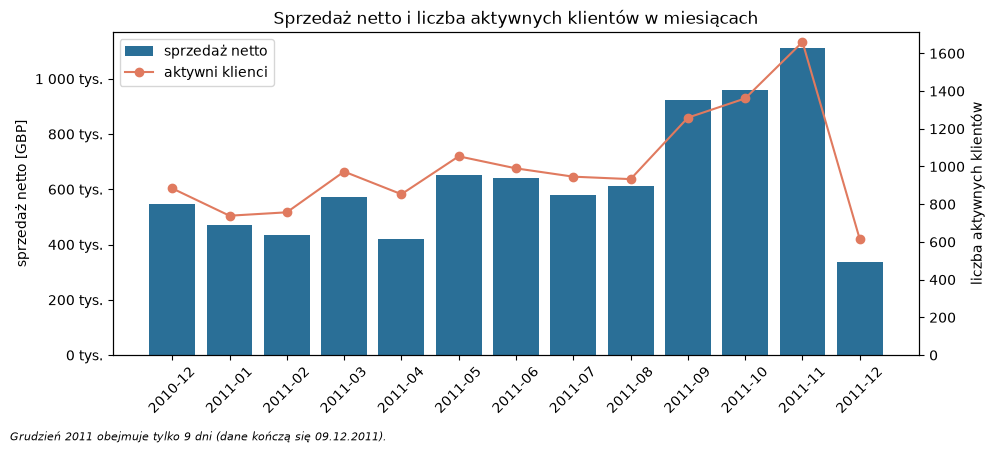

In [14]:
miesiace = eda.sprzedaz_miesieczna(dane)
fig = wykresy.wykres_sprzedazy_miesiecznej(
    miesiace, uwaga="Grudzień 2011 obejmuje tylko 9 dni (dane kończą się 09.12.2011)."
)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "01_sprzedaz_miesieczna.png")
fig

In [15]:
miesiace

,sprzedaz_brutto,anulowania,faktury,aktywni_klienci,sprzedaz_netto
miesiac,,,,,
2010-12,"565 199,56","17 305,64",1394,884,"547 893,92"
2011-01,"562 682,91","91 252,57",983,739,"471 430,34"
2011-02,"442 293,59","8 275,42",992,757,"434 018,17"
2011-03,"583 143,85","10 005,80",1312,973,"573 138,05"
2011-04,"454 440,88","33 313,11",1139,853,"421 127,77"
2011-05,"659 242,49","8 928,25",1544,1054,"650 314,24"
2011-06,"653 264,92","12 635,71",1390,990,"640 629,21"
2011-07,"591 603,79","11 389,06",1321,946,"580 214,73"
2011-08,"635 514,38","22 909,25",1267,933,"612 605,13"


*Obserwacja:* od września do listopada 2011 sprzedaż netto rośnie z ok. 0,6 do 1,1 mln GBP miesięcznie,
a liczba aktywnych klientów z ok. 930 do 1 660. Spadek w grudniu 2011 wynika z niepełnego miesiąca
(oraz anulowania zamówienia na 168 tys. GBP 9 grudnia).

*Interpretacja:* sprzedaż ma wyraźną sezonowość przedświąteczną. Ma to znaczenie dla cechy Recency liczonej
na 10.12.2011 – klienci kupujący głównie przed świętami wyglądają na „aktywnych”, a klienci sezonowi
z innych okresów mogą wyglądać na utraconych, choć wrócą w kolejnym sezonie.

### 4.3 Struktura geograficzna

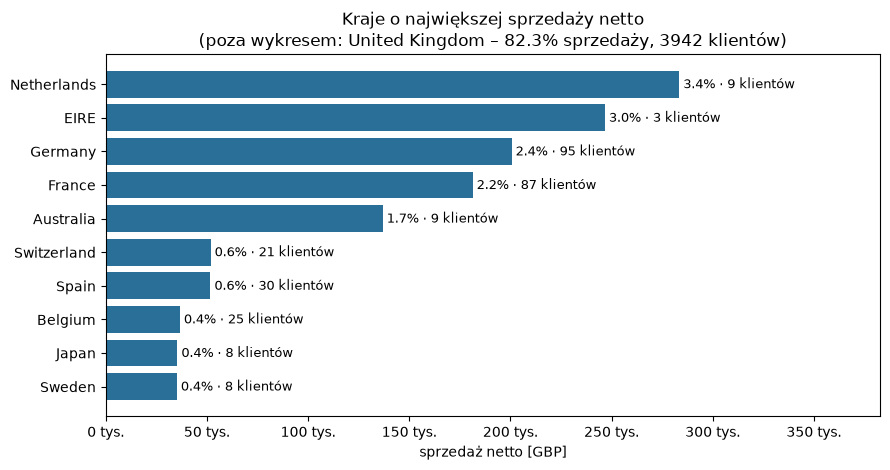

In [16]:
kraje = eda.sprzedaz_wg_kraju(dane, n=11)
fig = wykresy.wykres_krajow(kraje)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "02_kraje.png")
fig

*Obserwacja:* Wielka Brytania to 82,3% sprzedaży netto i 3 942 z 4 362 klientów (90%).
Holandia (9 klientów) i Irlandia (3 klientów) generują łącznie 6,4% sprzedaży.

*Interpretacja:* wnioski z segmentacji opisują przede wszystkim klientów brytyjskich. Wysoka sprzedaż
przy kilku klientach w niektórych krajach sugeruje odbiorców hurtowych – takie obserwacje będą
skrajne w cechach wartości.

### 4.4 Kiedy klienci składają zamówienia

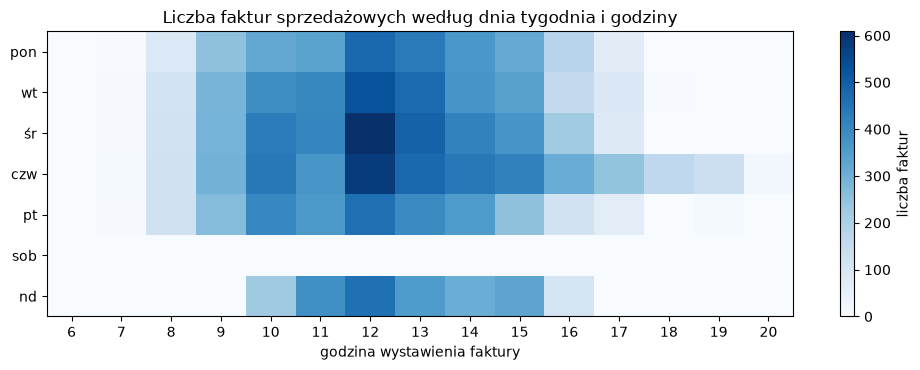

In [17]:
tydzien = eda.aktywnosc_tygodniowa(dane)
fig = wykresy.wykres_aktywnosci_tygodniowej(tydzien)
wykresy.zapisz_wykres(fig, KATALOG_WYKRESOW / "03_aktywnosc_tygodniowa.png")
fig

*Obserwacja:* w danych nie ma żadnej faktury z soboty; zamówienia składane są w godzinach 6–20,
najczęściej około południa, w niedziele tylko między 10 a 16.

*Interpretacja:* rozkład przypomina rytm pracy firm, co jest spójne z informacją, że wielu klientów
to hurtownicy. Brak sobót to raczej cecha systemu lub organizacji sklepu niż zachowania klientów –
nie wyciągamy z niego wniosków o preferencjach.

### 4.5 Anulowania i zwroty

In [18]:
eda.udzial_anulowan(dane).to_frame("wartość [%]")

,wartość [%]
faktury_proc,"15,53"
pozycje_proc,"2,130"
wartosc_proc,"5,400"
klienci_z_anulowaniem_proc,"35,17"


*Obserwacja:* 15,5% faktur to faktury anulujące, ale korygują one tylko 5,4% wartości sprzedaży;
co trzeci klient (35%) ma co najmniej jedno anulowanie.

*Interpretacja:* anulowania są częste, ale zwykle dotyczą małych kwot. Pominięcie ich zawyżałoby wartość
części klientów (skrajny przypadek: klient 12346, którego jedyne zamówienie za 77 tys. GBP zostało
anulowane w całości), dlatego Monetary liczymy netto.